# Лабораторная работа № 4 — Baselines и валидация временных рядов

**Цель:** сравнить простые модели прогнозирования и схемы временной валидации.  
**Данные:** дневная средняя мощность потребления электроэнергии за 2007 год ([UCI](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption)). Период сезонности — 7 дней, горизонт прогноза — 7 дней.

## 1. Загрузка данных

Дневной ряд: 365 наблюдений; пропущенных дней после ffill: 0


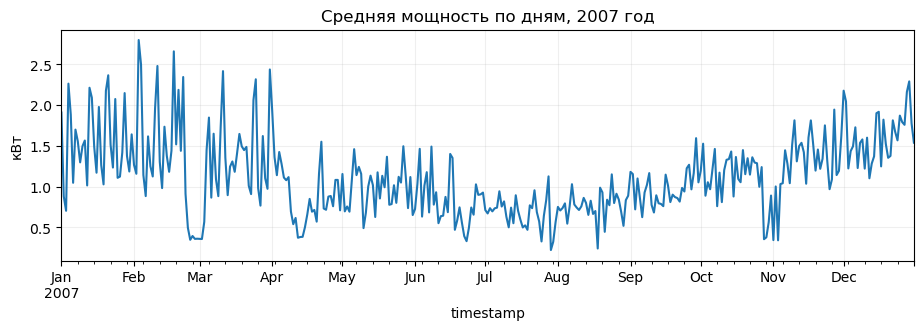

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from statsmodels.tsa.forecasting.theta import ThetaModel

url = (
    "https://archive.ics.uci.edu/static/public/235/"
    "individual+household+electric+power+consumption.zip"
)
df = pd.read_csv(
    url, compression="zip", sep=";",
    usecols=["Date", "Time", "Global_active_power"], na_values=["?"]
)
df["timestamp"] = pd.to_datetime(
    df["Date"] + " " + df["Time"], format="%d/%m/%Y %H:%M:%S"
)
df["Global_active_power"] = pd.to_numeric(df["Global_active_power"], errors="coerce")

hourly = (df.sort_values("timestamp").drop_duplicates("timestamp")
          .set_index("timestamp")["Global_active_power"]
          .loc["2007"].resample("h").mean())
series = hourly.resample("D").mean().ffill()

print(f"Дневной ряд: {len(series)} наблюдений; пропущенных дней после ffill: {series.isna().sum()}")
series.plot(figsize=(11, 3), title="Средняя мощность по дням, 2007 год", ylabel="кВт")
plt.grid(alpha=0.2)
plt.show()

## 2. Baseline-модели

In [2]:
H, season, steps = 7, 7, 10
window = 4 * season   # 4 недели для sliding window

def forecast(train, h, method):
    train = np.asarray(train, dtype=float)
    if method == "Naive":
        return np.repeat(train[-1], h)
    if method == "Seasonal Naive":
        return np.tile(train[-season:], int(np.ceil(h / season)))[:h]
    if method == "Mean":
        return np.repeat(train.mean(), h)
    if method == "Drift":
        slope = (train[-1] - train[0]) / (len(train) - 1)
        return train[-1] + slope * np.arange(1, h + 1)
    if method == "Theta":
        return np.asarray(ThetaModel(train, period=season, deseasonalize=True)
                          .fit().forecast(h), dtype=float)
    raise ValueError(method)

models = ["Naive", "Seasonal Naive", "Mean", "Drift", "Theta"]

## 3. Expanding и Sliding Window

In [3]:
# Последние 10 недель — тестовые окна, одинаковые для обеих схем.
y = series.to_numpy()
origins = range(len(y) - steps * H, len(y), H)

def backtest(scheme):
    records = []
    for fold, start in enumerate(origins, 1):
        train = y[:start] if scheme == "Expanding" else y[start-window:start]
        actual = y[start:start+H]
        scale = np.mean(np.abs(train[season:] - train[:-season]))
        for model in models:
            pred = forecast(train, H, model)
            for horizon, (true, estimate) in enumerate(zip(actual, pred), 1):
                records.append((scheme, model, fold, horizon,
                                series.index[start + horizon - 1],
                                true, estimate, scale))
    return pd.DataFrame(records, columns=[
        "Схема", "Модель", "Окно", "Горизонт", "Дата", "Факт", "Прогноз", "Масштаб"
    ])

predictions = pd.concat([backtest("Expanding"), backtest("Sliding")], ignore_index=True)
print(f"Оценено {steps} тестовых недель по {H} дней для каждой схемы.")

Оценено 10 тестовых недель по 7 дней для каждой схемы.


## 4. Метрики и сравнение

In [4]:
def metrics(g):
    actual, pred = g["Факт"].to_numpy(), g["Прогноз"].to_numpy()
    error = actual - pred
    den_smape = np.abs(actual) + np.abs(pred)
    # MASE нормируем на сезонный Naive внутри соответствующих train-окон.
    return pd.Series({
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error**2)),
        "MAPE, %": np.mean(np.abs(error) / actual) * 100 if np.all(actual != 0) else np.nan,
        "sMAPE, %": np.mean(np.divide(200 * np.abs(error), den_smape,
                                     out=np.zeros_like(error), where=den_smape != 0)),
        "MASE": np.mean(np.abs(error) / g["Масштаб"].to_numpy()),
    })

table = predictions.groupby(["Схема", "Модель"], sort=False)[["Факт", "Прогноз", "Масштаб"]].apply(metrics)
display(table.round(3))

for scheme in ["Expanding", "Sliding"]:
    part = table.loc[scheme]
    print(f"{scheme}: лучший по MASE — {part['MASE'].idxmin()}; "
          f"по MAE — {part['MAE'].idxmin()}; по RMSE — {part['RMSE'].idxmin()}")

MAE   RMSE  MAPE, %  sMAPE, %   MASE
Схема     Модель                                                
Expanding Naive           0.322  0.416   26.397    27.015  0.974
          Seasonal Naive  0.367  0.479   37.619    31.494  1.114
          Mean            0.432  0.522   35.905    34.704  1.305
          Drift           0.327  0.421   26.553    27.552  0.990
          Theta           0.299  0.388   28.309    24.592  0.904
Sliding   Naive           0.322  0.416   26.397    27.015  0.999
          Seasonal Naive  0.367  0.479   37.619    31.494  1.175
          Mean            0.305  0.394   30.159    24.560  0.923
          Drift           0.346  0.442   28.919    31.918  1.089
          Theta           0.301  0.394   27.450    25.190  0.909

Expanding: лучший по MASE — Theta; по MAE — Theta; по RMSE — Theta
Sliding: лучший по MASE — Theta; по MAE — Theta; по RMSE — Theta


## 5. Прогноз на последнюю неделю

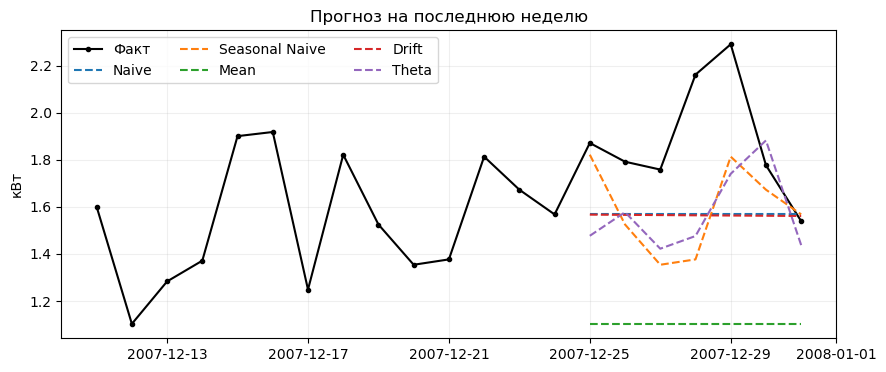

In [5]:
last = predictions[(predictions["Схема"] == "Expanding") &
                   (predictions["Окно"] == steps)]
plt.figure(figsize=(10, 4))
plt.plot(series.iloc[-21:].index, series.iloc[-21:], "k.-", label="Факт")
for model in models:
    part = last[last["Модель"] == model]
    plt.plot(part["Дата"], part["Прогноз"], "--", label=model)
plt.title("Прогноз на последнюю неделю")
plt.ylabel("кВт")
plt.legend(ncol=3)
plt.grid(alpha=0.2)
plt.show()

## 6. Интервалы: Coverage и Width

Для Seasonal Naive квантили ошибок первых 6 недель используем как калибровку, а последние 4 недели — для проверки. Калибровочные данные не пересекаются с проверочными. При шести калибровочных неделях интервалы носят иллюстративный характер.

,"Coverage, %","Width, кВт"
Горизонт,,
1,100.0,1.542
2,50.0,0.746
3,100.0,1.492
4,75.0,0.871
5,100.0,2.242
6,100.0,1.964
7,100.0,1.348


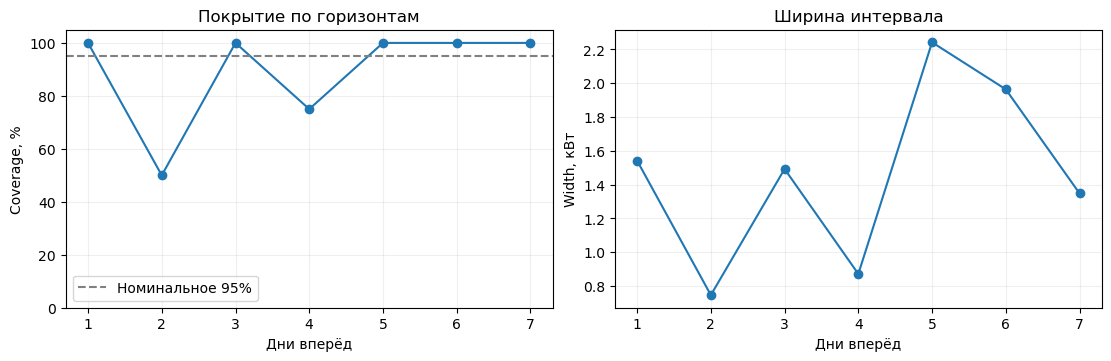

In [6]:
seasonal = predictions[(predictions["Схема"] == "Expanding") &
                       (predictions["Модель"] == "Seasonal Naive")].copy()
seasonal["Ошибка"] = seasonal["Факт"] - seasonal["Прогноз"]
calibration = seasonal[seasonal["Окно"] <= 6]
evaluation = seasonal[seasonal["Окно"] > 6].copy()

quantiles = calibration.groupby("Горизонт")["Ошибка"].quantile([0.025, 0.975]).unstack()
quantiles.columns = ["q_low", "q_high"]
evaluation = evaluation.join(quantiles, on="Горизонт")
evaluation["Нижняя"] = evaluation["Прогноз"] + evaluation["q_low"]
evaluation["Верхняя"] = evaluation["Прогноз"] + evaluation["q_high"]
evaluation["Попал"] = ((evaluation["Факт"] >= evaluation["Нижняя"]) &
                       (evaluation["Факт"] <= evaluation["Верхняя"]))
evaluation["Ширина"] = evaluation["Верхняя"] - evaluation["Нижняя"]

interval_table = evaluation.groupby("Горизонт").agg(
    **{"Coverage, %": ("Попал", lambda x: x.mean() * 100),
       "Width, кВт": ("Ширина", "mean")}
)
display(interval_table.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
ax[0].plot(interval_table.index, interval_table["Coverage, %"], "o-")
ax[0].axhline(95, color="gray", ls="--", label="Номинальное 95%")
ax[0].set(title="Покрытие по горизонтам", xlabel="Дни вперёд", ylabel="Coverage, %", ylim=(0, 105))
ax[0].legend()
ax[1].plot(interval_table.index, interval_table["Width, кВт"], "o-")
ax[1].set(title="Ширина интервала", xlabel="Дни вперёд", ylabel="Width, кВт")
for a in ax:
    a.grid(alpha=0.2)
plt.show()

## 7. Случайный split и утечка

Намеренно неправильная проверка: случайно отделяем тестовые дни, а для прогноза берём **ближайшее** обучающее наблюдение, даже если оно находится **в будущем**. Сравним с использованием только предыдущего известного значения на тех же тестовых днях. Это демонстрация look-ahead leakage, а не корректный backtesting.

In [7]:
indices = np.arange(len(y))
train_idx, test_idx = train_test_split(indices, test_size=0.2, random_state=42, shuffle=True)
train_idx.sort()
test_idx.sort()
# Для каждого тестового дня нужен хотя бы один более ранний обучающий день.
test_idx = test_idx[test_idx > train_idx[0]]

positions = np.searchsorted(train_idx, test_idx)
left = train_idx[np.clip(positions - 1, 0, len(train_idx)-1)]
right = train_idx[np.clip(positions, 0, len(train_idx)-1)]
nearest = np.where(np.abs(test_idx - right) < np.abs(test_idx - left), right, left)

# Наивный прогноз с доступом к будущему (некорректный).
leaky_pred = y[nearest]
# Прогноз исключительно по предыдущему известному дню.
past_pred = y[left]

leak_mae = np.mean(np.abs(y[test_idx] - leaky_pred))
past_mae = np.mean(np.abs(y[test_idx] - past_pred))
future_share = np.mean(nearest > test_idx) * 100
print(f"Случайный split, ближайший сосед (с утечкой): MAE = {leak_mae:.3f} кВт")
print(f"Те же дни, только предыдущий сосед:     MAE = {past_mae:.3f} кВт")
print(f"В {future_share:.1f}% тестовых случаев использовано будущее наблюдение.")
print("Случайный split не заменяет expanding/sliding backtesting; задачи оценки различаются.")

Случайный split, ближайший сосед (с утечкой): MAE = 0.325 кВт
Те же дни, только предыдущий сосед:     MAE = 0.322 кВт
В 15.3% тестовых случаев использовано будущее наблюдение.
Случайный split не заменяет expanding/sliding backtesting; задачи оценки различаются.


## 8. Выводы

In [8]:
for scheme in ["Expanding", "Sliding"]:
    sub = table.loc[scheme]
    print(f"{scheme}: лучший baseline — {sub['MASE'].idxmin()} "
          f"(MASE = {sub['MASE'].min():.3f}).")

print(f"Интервалы Seasonal Naive: Coverage = {evaluation['Попал'].mean()*100:.1f}%, "
      f"Width = {evaluation['Ширина'].mean():.3f} кВт.")

print("Случайный split: использование будущих наблюдений делает валидацию некорректной.")

Expanding: лучший baseline — Theta (MASE = 0.904).
Sliding: лучший baseline — Theta (MASE = 0.909).
Интервалы Seasonal Naive: Coverage = 89.3%, Width = 1.458 кВт.
Случайный split: использование будущих наблюдений делает валидацию некорректной.


1. Лучшей baseline-моделью по MASE оказалась **Theta**: 0.904 для Expanding и 0.909 для Sliding Window. По MAE и RMSE она также показала лучшие или сопоставимые результаты.

2. По MAPE лидирует Naive, что показывает зависимость ранжирования моделей от выбранной метрики. Для оценки ошибок в кВт наиболее понятна MAE, а MASE позволяет сравнивать качество с сезонным наивным прогнозом.

3. Интервальные прогнозы Seasonal Naive обеспечили среднее покрытие **89.3%** при средней ширине **1.458 кВт**. Покрытие оказалось ниже номинального уровня 95%.

4. При случайном разбиении в **15.3%** тестовых случаев использовались будущие наблюдения. Однако MAE составила 0.325 кВт против 0.322 кВт при использовании только предыдущего наблюдения. Таким образом, утечка не улучшила результат в данном эксперименте, но продемонстрировала некорректность случайной валидации.

5. Для исследуемого ряда предпочтительнее **Theta**. Корректную оценку качества обеспечивают временные схемы backtesting, исключающие использование будущих данных.

<!--  -->